In V1 we have:
- Fixed number of Byzantine nodes in every epochs(3 out of 10)
- Byzantine nodes implemented captions mixing to poison the model

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os
import re
import csv
import time
import pickle
import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from torchvision import transforms
from datasets import load_dataset
import torchvision.models as models
from collections import OrderedDict
from torchvision.models import ResNet50_Weights
from collections import Counter
from PIL import Image
import numpy as np
import random

from tqdm import tqdm

In [ ]:
EMBED_DIM = 256
HIDDEN_DIM = 512
# lower the lr
LEARNING_RATE = 0.0001
BATCH_SIZE = 8
EPOCHS = 50
MIN_WORD_FREQ = 1
SEED = 42
device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
NUM_WORKERS = 2
NUM_NODES = 10
NUM_BAD = 2
TO_KEEP = 6
BEST_CHECKPOINT_PATH = "best_checkpoint.pth"  # Checkpoint w/ epoch, model, optimizer, best_val_loss
FINAL_MODEL_PATH = "final_model.pth"          # Final model weights only (saved at the end)
VOCAB_PATH = "vocab.pkl"                      # Where we save the vocabulary

# Set this to True if you want to resume from the best checkpoint
RESUME = False

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [ ]:
device

'cuda'

In [ ]:
class Vocabulary:
  def __init__(self, freq_threshold=5):
    self.freq_threshold = freq_threshold
    # self.itos = {0: "<pad>", 1: "<start>", 2: "<end>", 3: "<unk>"}
    self.itos = {0: "pad", 1: "startofseq", 2: "endofseq", 3: "unk"}
    self.stoi = {v: k for k, v in self.itos.items()}
    self.index = 4

  def __len__(self):
    return len(self.itos)

  def tokenizer(self, text):
    text = text.lower()
    """ split the sentence into words """
    """ note that if you use \w, it'll split it into characters """
    tokens = re.findall(r"\w+", text)
    return tokens

  def build_vocabulary(self, sentence_list):
    frequencies = Counter()
    for sentence in sentence_list:
      tokens = self.tokenizer(sentence)
      frequencies.update(tokens)

    for word, freq in frequencies.items():
      if freq >= self.freq_threshold:
        """ previously index set to 4 because we have 4 predefined tokens(in the initial itos) """
        self.stoi[word] = self.index
        self.itos[self.index] = word
        self.index += 1

  """ allow for netural network to process """
  def numericalize(self, text):
    tokens = self.tokenizer(text)
    numericalized = []
    for token in tokens:
      if token in self.stoi:
        numericalized.append(self.stoi[token])
      else:
        numericalized.append(self.stoi["<unk>"])
    return numericalized


<>:15: SyntaxWarning: invalid escape sequence '\w'
<>:15: SyntaxWarning: invalid escape sequence '\w'
/tmp/ipython-input-119331113.py:15: SyntaxWarning: invalid escape sequence '\w'
  """ note that if you use \w, it'll split it into characters """


In [ ]:
image_size = 256
train_transform = transforms.Compose([transforms.Resize((image_size, image_size)),
  transforms.Lambda(lambda x: x.convert('RGB')),
  transforms.RandomHorizontalFlip(),
  transforms.ToTensor(),
  transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])])
dataset = load_dataset("TeeA/Pokemon-Captioning-Classification", split="train")
# dataset = load_dataset("jugg1024/pokemon-gpt4o-captions", split="train")
dataset

Dataset({
    features: ['image_file_path', 'image', 'labels', 'caption'],
    num_rows: 4869
})

In [ ]:
vocab = Vocabulary(freq_threshold=MIN_WORD_FREQ)
vocab.build_vocabulary(dataset["caption"])
vocab_size = len(vocab)
vocab_size

1779

In [ ]:
# @title
def preprocess(data):
  data["image"] = train_transform(data["image"])
  numercial_cap = [vocab.stoi["startofseq"]]
  numercial_cap += (vocab.numericalize(data["caption"]))
  numercial_cap.append(vocab.stoi["endofseq"])
  data["text"] = numercial_cap
  # data["caption"] = vocab.stoi["startofseq"] + data['en_text'] + vocab.stoi["endofseq"]
  return data

dataset = dataset.map(preprocess, remove_columns=['image_file_path', 'labels', 'caption'],)

In [ ]:
dataset.set_format("torch", columns=["image", "text"])
dataset

Dataset({
    features: ['image', 'text'],
    num_rows: 4869
})

In [ ]:
from torch.utils.data import random_split

dataset.shuffle()
train_dataset = dataset.select(range(4500))
test_dataset = dataset.select(range(4500, 4869))

In [ ]:
len(train_dataset)

4500

In [ ]:
def collate_fn(batch):
  batch.sort(key=lambda x: len(x["text"]), reverse=True)
  images = [item["image"] for item in batch]
  captions = [item["text"] for item in batch]
  lengths = [len(cap) for cap in captions]
  max_len = max(lengths)

  padded_captions = torch.zeros(len(captions), max_len, dtype=torch.long)
  for i, cap in enumerate(captions):
    end = lengths[i]
    padded_captions[i, :end] = cap[:end]

  images = torch.stack(images, dim=0)
  return images, padded_captions, lengths

def collate_fn_malicious(batch):
  # batch.sort(key=lambda x: len(x["caption"]), reverse=True)
  images = [item["image"] for item in batch]
  captions = [item["text"] for item in batch]
  lengths = [len(cap) for cap in captions]

  shuffled_indices = torch.randperm(len(captions))

  shuffled_captions = [captions[i] for i in shuffled_indices]
  shuffled_lengths = [lengths[i] for i in shuffled_indices]
  max_len = max(shuffled_lengths)

  padded_captions = torch.zeros(len(shuffled_captions), max_len, dtype=torch.long)
  for i, cap in enumerate(shuffled_captions):
    end = shuffled_lengths[i]
    padded_captions[i, :end] = cap[:end]

  images = torch.stack(images, dim=0)
  return images, padded_captions, shuffled_lengths

In [ ]:
import random

random.seed(SEED)
identity = [1, 1] + [0]*(NUM_NODES - 2)
random.shuffle(identity)
identity

[0, 0, 0, 0, 0, 0, 0, 0, 1, 1]

In [ ]:
train_dataloader = []
partition_size = len(train_dataset)//NUM_NODES

for i, id in enumerate(identity):
  if id == 0:
    dataloader_i = torch.utils.data.DataLoader(
    train_dataset.select(range(i*partition_size, (i+1)*partition_size)), batch_size=BATCH_SIZE, collate_fn=collate_fn, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True,
    )
  else:
    dataloader_i = torch.utils.data.DataLoader(
    train_dataset.select(range(i*partition_size, (i+1)*partition_size)), batch_size=BATCH_SIZE, collate_fn=collate_fn_malicious, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True,
    )
  train_dataloader.append(dataloader_i)

In [ ]:
# @title
class ResNetEncoder(nn.Module):
  def __init__(self, embed_dim):
    super().__init__()
    resnet = models.resnet50(weights=ResNet50_Weights.DEFAULT)
    """ train only newly defined layers, freeze the pretrained layers """
    for param in resnet.parameters():
      param.requires_grad = False
    """ move off the last layer: FC (2048 -> 1000) """
    modules = list(resnet.children())[:-1]
    self.resnet = nn.Sequential(*modules)

    self.fc = nn.Linear(resnet.fc.in_features, embed_dim)
    self.batch_norm = nn.BatchNorm1d(embed_dim, momentum=0.01)

  def forward(self, images):
    # with torch.no_grad():
      # (bz, 2048, 1, 1)
    features = self.resnet(images)
    # (bz, 2048, 1, 1) -> (bz, 2048)
    features = features.view(features.size(0), -1) # '-1' implies to calculate the other dimension automatically
    features = self.fc(features)
    features = self.batch_norm(features)
    return features


class LSTMDecoder(nn.Module):
  def __init__(self, embed_dim, hidden_dim, vocab_size, num_layers=2):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, embed_dim)
    # to fix overfitting
    self.dropout = nn.Dropout(0.4)
    self.lstm = nn.LSTM(embed_dim*2, hidden_dim, num_layers, batch_first=True, dropout=0.4)
    self.attention = nn.MultiheadAttention(embed_dim, num_heads=4, batch_first=True)
    self.fc = nn.Linear(hidden_dim, vocab_size)

  def forward(self, features, caption):
    caption = caption[:, :-1]
    emb = self.embedding(caption)
    emb = self.dropout(emb)

    features_expanded = features.unsqueeze(1).repeat(1, emb.size(1), 1)
    attn_output, _ = self.attention(emb, features_expanded, features_expanded)

    lstm_input = torch.cat((attn_output, emb), dim=-1)
    outputs, _ = self.lstm(lstm_input)
    logits = self.fc(outputs)
    return logits


class ImageCaptioningModel(nn.Module):
  def __init__(self, encoder, decoder):
    super().__init__()
    self.encoder = encoder
    self.decoder = decoder

  def forward(self, images, captions):
    features = self.encoder(images)
    outputs = self.decoder(features, captions)
    return outputs

In [ ]:
def train_by_epoch(model, dataloader, criterion, optimizer, vocab_size):
  model.train()
  total_loss = 0
  progress_bar = tqdm(dataloader, unit="batch")
  for images, captions, _lengths in progress_bar:
    images = images.to(device)
    captions = captions.to(device)

    optimizer.zero_grad()
    # (bz, seq_len, vocab_size)
    outputs = model(images, captions)
    # outputs = outputs[:, 1:, :].contiguous().view(-1, vocab_size)
    outputs = outputs.contiguous().view(-1, vocab_size)

    targets = captions[:, 1:].contiguous().view(-1)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    total_loss += loss.item()
    progress_bar.set_postfix({"loss": f"{loss.item():.4f}"})
  avg_loss = total_loss / len(dataloader)
  return avg_loss

def validate(model, dataloader, criterion, vocab_size):
  model.eval()
  total_loss = 0
  with torch.no_grad():
    for images, captions, _lengths in dataloader:
      images = images.to(device)
      captions = captions.to(device)
      outputs = model(images, captions)
      # outputs = outputs[:, 1:, :].contiguous().view(-1, vocab_size)
      outputs = outputs.contiguous().view(-1, vocab_size)
      targets = captions[:, 1:].contiguous().view(-1)

      loss = criterion(outputs, targets)
      total_loss += loss.item()
    avg_val_loss = total_loss / len(dataloader)
    return avg_val_loss

In [ ]:
encoder = ResNetEncoder(EMBED_DIM)
decoder = LSTMDecoder(EMBED_DIM, HIDDEN_DIM, vocab_size)
model = ImageCaptioningModel(encoder, decoder).to(device)

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
print(f"{total_params:,} total parameters.")
total_trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad)
print(f"{total_trainable_params:,} training parameters.")

29,866,803 total parameters.
6,358,771 training parameters.


In [ ]:
CONS_EPOCH = 30
COSINE_EPOCH = EPOCHS - CONS_EPOCH
criterion = nn.CrossEntropyLoss(ignore_index=vocab.stoi["pad"])
parameters = (
  list(model.decoder.parameters()) + list(model.encoder.fc.parameters())
  + list(model.encoder.batch_norm.parameters()) )
optimizer = optim.AdamW(parameters, lr=LEARNING_RATE, weight_decay=0.01)
constant_scheduler = optim.lr_scheduler.ConstantLR(
    optimizer,
    factor=1.0,
    total_iters=CONS_EPOCH
)
cosine_scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=COSINE_EPOCH,
    eta_min=LEARNING_RATE * 0.1,
    last_epoch=-1
)

scheduler = optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[constant_scheduler, cosine_scheduler],
    milestones=[CONS_EPOCH]
)
start_epoch = 0
best_val_loss = float("inf")

Nodes Definition

In [ ]:
class Node:
  def __init__(self,
    init_model,
    trainloader,
    optimizer,
    criterion,
    vocab_size,
    device,
  ) -> None:
    self.model = init_model
    self.collate_fn = collate_fn,
    self.criterion = criterion
    self.optimizer = optimizer
    self.vocab_size = vocab_size
    self.trainloader = trainloader
    self.device = device

  def set_parameters(self, trainable_parameters):
    trainable_params = [p for p in self.model.parameters() if p.requires_grad]

    if len(trainable_parameters) != len(trainable_params):
        raise ValueError(f"num unmatched: expected {len(trainable_params)}, but have {len(trainable_parameters)}")

    for param, param_array in zip(trainable_params, trainable_parameters):
        tensor = torch.tensor(param_array, device=param.device)
        param.data.copy_(tensor)

  def get_parameters(self):
    params = [param.detach().cpu().numpy()
        for param in self.model.parameters()
        if param.requires_grad
    ]
    return params

  def fit(self):
    train_loss = train_by_epoch(self.model, self.trainloader, self.criterion, self.optimizer, self.vocab_size)
    return self.get_parameters(), len(self.trainloader)

In this version, poison the model by data collate_fn_malicious()

In [ ]:
# @title
""" Multi-Krum """
def aggregate(results):
  # print(f"num of results: {len(results)}")
  # print(f"element of result: {len(results[0])}")
  weights_list = []
  for w, _ in results:
    weight_tensors = [torch.tensor(p, device=device) if isinstance(p, np.ndarray) else p for p in w]
    weights_list.append(weight_tensors)

  num_examples_list = torch.tensor([n for _, n in results], dtype=torch.float32, device=device)
  total_examples = num_examples_list.sum()

  return [
      torch.stack([w[i] * n for w, n in zip(weights_list, num_examples_list)]).sum(dim=0) / total_examples
      for i in range(len(weights_list[0]))
  ]

def compute_distances(weights):
  flat_w = torch.stack([torch.cat([torch.tensor(p).flatten() if isinstance(p, np.ndarray) else p.flatten()
    for p in w]) for w in weights])
  return torch.cdist(flat_w, flat_w, p=2) ** 2

def aggregate_mkrum(results, num_malicious, to_keep):
  n = len(results)
  if n < num_malicious + 2:
    raise ValueError("Not enough nodes")

  weights = [w for w, _ in results]
  # print(f"len of weights: {len(weights)}")
  # print(f"type of w and len of w: {type(weights[0])} -- {len(weights[0])}")
  distance_matrix = compute_distances(weights)
  num_closest = max(1, int(n - num_malicious - 2))
  closest_indices = []
  scores = []
  for i in range(n):
    distances = distance_matrix[i]
    sorted_idx = np.argsort(distances)
    mask = (sorted_idx != i)
    closest = sorted_idx[mask][:num_closest]
    score = torch.sum(distances[closest]).item()
    scores.append(score)

  # scores = [
  #     np.sum(distance_matrix[i, closest_indices[i]].cpu().numpy())
  #     for i in range(n)
  # ]

  # if len(weights) - to_keep <= 2 * (num_malicious + 1):
  #   to_keep = len(weights) // 2
  scores = np.array(scores)
  best_indices = np.argsort(scores)[:to_keep]
  best_results = [results[i] for i in best_indices]
  return aggregate(best_results)

Initialize nodes

In [ ]:
# @title
Nodes = []

for i in identity:
  if i == 0:
    Nodes.append(Node(init_model=model, trainloader=train_dataloader[i], optimizer=optimizer,
      criterion=criterion, vocab_size=vocab_size, device=device))
  else:
    Nodes.append(Node(init_model=model, trainloader=train_dataloader[i], optimizer=optimizer,
      criterion=criterion, vocab_size=vocab_size, device=device))

In [ ]:
def get_parameters(model):
  params = [
      param.detach().cpu().numpy()
      for param in model.parameters()
      if param.requires_grad
  ]
  return params

def update(model, fit_res):
  update_param = aggregate_mkrum(fit_res, NUM_BAD, TO_KEEP)
  trainable_params = [p for p in model.parameters() if p.requires_grad]

  if len(update_param) != len(trainable_params):
    raise ValueError(f"num unmatched: expected {len(trainable_params)}, but have {len(update_param)}")

  for param, param_array in zip(trainable_params, update_param):
      tensor = torch.tensor(param_array, device=param.device)
      param.data.copy_(tensor)

Training Loop

In [ ]:
losses = []
global_parameters = get_parameters(model)
valdataloader = torch.utils.data.DataLoader(
    test_dataset, batch_size=BATCH_SIZE, collate_fn=collate_fn, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True,
)
print(len(global_parameters))

19


In [ ]:
for epoch in range(EPOCHS):
  print(f"Learning Rate: {optimizer.param_groups[0]['lr']}")
  fit_results = []
  for i in range(NUM_NODES):
    node_i = Nodes[i]
    node_i.set_parameters(global_parameters)
    fit_res = node_i.fit()
    fit_results.append(fit_res)

  update(model, fit_results)
  global_parameters = get_parameters(model)
  val_loss = validate(model, valdataloader, criterion, vocab_size)
  scheduler.step()
  if val_loss < best_val_loss:
    best_val_loss = val_loss
    checkpoint_dict = {
      "epoch": epoch,
      "model_state_dict": model.state_dict(),
      "optimizer_state_dict": optimizer.state_dict(),
      "best_val_loss": best_val_loss
    }
    torch.save(checkpoint_dict, BEST_CHECKPOINT_PATH)
    print(f"New best model saved -> {BEST_CHECKPOINT_PATH} (val_loss={val_loss:.4f})")
  print(f"Epoch {epoch}, loss: {val_loss}")
  losses.append(val_loss)

In [ ]:
final_checkpoint_dict = {"model_state_dict": model.state_dict(),}
torch.save(final_checkpoint_dict, FINAL_MODEL_PATH)

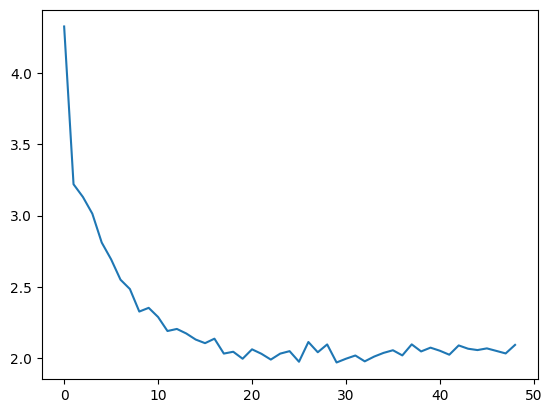

In [ ]:
plt.plot(losses)